# Chapitre 9 - Cours 5 : fautes byzantines, modèles de système et correction

Jusqu'ici, les nœuds étaient lents, absents ou mal informés, mais **honnêtes**. Que se
passe-t-il s'ils peuvent mentir ? Et comment raisonner rigoureusement sur un algorithme
quand tout peut défaillir ? Ce notebook traite des fautes **byzantines**, des **modèles
de système** (hypothèses explicites sur ce qui peut mal tourner) et de la définition de
la **correction** d'un algorithme distribué par des propriétés de **sûreté** et de
**vivacité**. Il couvre la fin de *Knowledge, Truth, and Lies* : *Byzantine Faults*
(encadré *The Byzantine Generals Problem*, *Weak forms of lying*) et *System Model and
Reality* (*Defining the correctness of an algorithm*, *Distinguishing between safety and liveness*, *Mapping system models to
the real world*).

**Plan.**

1. Fautes byzantines et problème des généraux.
2. Quand faut-il tolérer les fautes byzantines ?
3. Les formes faibles de mensonge.
4. Modèles de système.
5. Correction d'un algorithme : sûreté et vivacité.
6. Des modèles au monde réel.

In [1]:
import itertools
from math import comb, prod

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Fautes byzantines et problème des généraux (section *Byzantine Faults*)

Les jetons de clôture du cours 4 bloquent un nœud qui se trompe **de bonne foi** (il ne
sait pas encore que son bail a expiré). Mais un nœud qui voudrait **délibérément**
subvertir le système n'aurait qu'à envoyer un faux jeton. Le livre suppose que les nœuds
sont **non fiables mais honnêtes** : lents, muets, mal informés (pause, délai réseau),
mais s'ils répondent, ils disent « la vérité » telle qu'ils la connaissent et respectent
le protocole. Un nœud qui peut **mentir** (réponses arbitrairement fausses, votes
contradictoires dans une même élection) commet une **faute byzantine** ; trouver un
consensus dans ces conditions est le **problème des généraux byzantins**.

**Les deux généraux** (encadré *The Byzantine Generals Problem*). Deux généraux, campés à
des endroits différents, doivent s'accorder sur un plan d'attaque ; ils ne communiquent
que par messagers, qui peuvent être retardés ou capturés, comme les paquets d'un réseau.

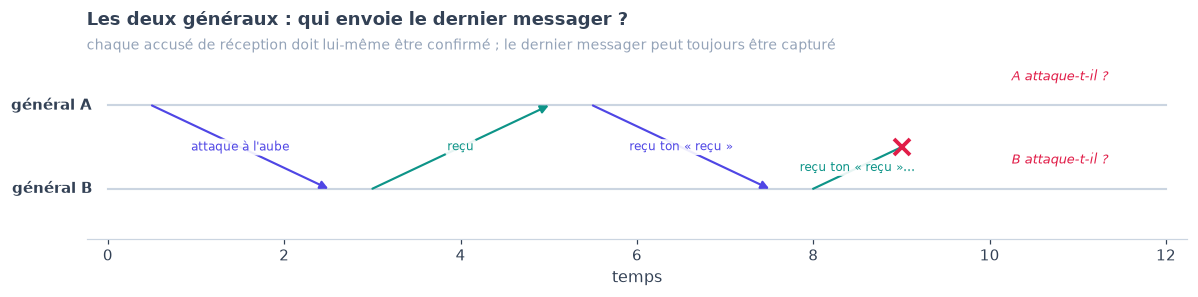

In [2]:
st = SpaceTime(["général A", "général B"], t_max=12, width=11, title="Les deux généraux : qui envoie le dernier messager ?",
               subtitle="chaque accusé de réception doit lui-même être confirmé ; le dernier messager peut toujours être capturé")
st.msg("général A", 0.5, "général B", 2.5, "attaque à l'aube", color=INDIGO)
st.msg("général B", 3.0, "général A", 5.0, "reçu", color=TEAL)
st.msg("général A", 5.5, "général B", 7.5, "reçu ton « reçu »", color=INDIGO)
st.msg("général B", 8.0, "général A", 10.0, "reçu ton « reçu »...", color=TEAL, lost=True)
st.note(10.8, "général B", "B attaque-t-il ?", dy=0.35, color=ROSE)
st.note(10.8, "général A", "A attaque-t-il ?", dy=0.35, color=ROSE)
st.show()

Aucun nombre fini de messages ne suffit : celui qui envoie le dernier ne sait pas s'il
est arrivé, et l'autre le sait. Le chapitre 10 reviendra sur ce problème
de consensus. Dans la version **byzantine**, $n$ généraux doivent s'accorder alors que
certains sont des **traîtres**, inconnus, qui envoient des messages faux pour semer la
confusion. (Byzance, devenue Constantinople puis Istanbul, n'avait pas de généraux plus
fourbes qu'ailleurs : le nom vient de l'adjectif « byzantin », compliqué et tortueux ;
Lamport cherchait une nationalité qui ne vexerait personne.)

**L'algorithme OM(m)** de Lamport, Shostak et Pease (1982, « oral messages ») résout le
problème avec $m$ traîtres : le commandant envoie un ordre à chaque lieutenant ; chaque
lieutenant relaie ce qu'il a reçu aux autres (récursivement, OM(m-1)) ; chacun décide à la
**majorité** des valeurs reçues. Il faut garantir :

- **IC1** : tous les lieutenants loyaux prennent la même décision ;
- **IC2** : si le commandant est loyal, ils exécutent son ordre.

`ds.byzantine_check` exécute OM(m) contre des traîtres qui mentent de **toutes** les
façons possibles (chaque message d'un traître peut valoir 0 ou 1, selon le destinataire et
le chemin), ou contre un échantillon de stratégies quand elles sont trop nombreuses.

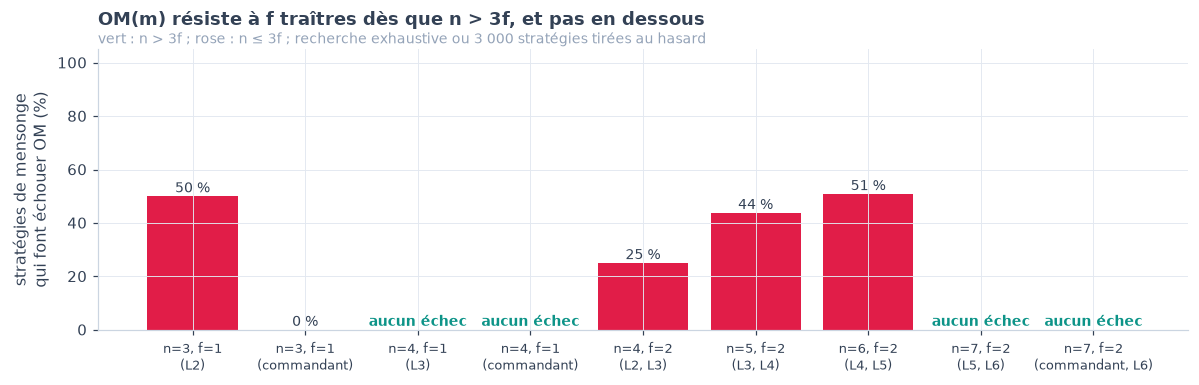

,n,m,traîtres,f,n > 3f ?,stratégies,échecs
0,3,1,L2,1,False,2,1
1,3,1,commandant,1,False,4,0
2,4,1,L3,1,True,4,0
3,4,1,commandant,1,True,8,0
4,4,1,"L2, L3",2,False,16,4
5,5,1,"L3, L4",2,False,64,28
6,6,2,"L4, L5",2,False,3000,1525
7,7,2,"L5, L6",2,True,3000,0
8,7,2,"commandant, L6",2,True,3000,0


In [3]:
cas = [(3, 1, {2}), (3, 1, {0}), (4, 1, {3}), (4, 1, {0}), (4, 1, {2, 3}), (5, 1, {3, 4}),
       (6, 2, {4, 5}), (7, 2, {5, 6}), (7, 2, {0, 6})]
rows = []
for n, m, tr in cas:
    r = ds.byzantine_check(n, m, tr, n_strategies=3000, seed=1)
    rows.append(dict(n=n, m=m, traîtres=", ".join("commandant" if t == 0 else f"L{t}" for t in sorted(tr)),
                     f=len(tr), **{"n > 3f ?": n > 3 * len(tr)}, stratégies=r["strategies"],
                     échecs=r["echecs"], exemple=r["exemple"]))
B = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 3.6))
lab = [f"n={r.n}, f={r.f}\n({r.traîtres})" for r in B.itertuples()]
taux = B.échecs / B.stratégies * 100
ax.bar(range(len(B)), taux, color=[TEAL if ok else ROSE for ok in B["n > 3f ?"]])
for i, (v, ok) in enumerate(zip(taux, B["n > 3f ?"])):
    ax.text(i, v + 1.5, f"{v:.0f} %" if v or not ok else "aucun échec", ha="center", fontsize=9,
            color=TEAL if ok else SLATE, fontweight="bold" if ok else None)
ax.set_xticks(range(len(B))); ax.set_xticklabels(lab, fontsize=8.5)
ax.set_ylabel("stratégies de mensonge\nqui font échouer OM (%)"); ax.set_ylim(0, 105)
ax.set_title("OM(m) résiste à f traîtres dès que n > 3f, et pas en dessous")
subtitle(ax, "vert : n > 3f ; rose : n ≤ 3f ; recherche exhaustive ou 3 000 stratégies tirées au hasard")
plt.tight_layout(); plt.show()
B.drop(columns="exemple")

Le résultat illustre le théorème : avec $f$ traîtres, il faut **plus de $3f$ généraux**
(plus des deux tiers loyaux). Avec 3 généraux et un lieutenant traître, une stratégie
sur deux suffit à tromper le lieutenant loyal : il reçoit « attaque » du commandant et
« le commandant a dit retraite » du traître, et ne peut pas savoir qui ment (il choisit
alors la valeur par défaut, contraire à l'ordre du commandant loyal). Avec 3 généraux et
un commandant traître, OM(1) s'en sort ici par chance (les deux lieutenants, à égalité,
choisissent la même valeur par défaut) : l'impossibilité porte sur le pire cas, et il
suffit qu'**une** position de traître fasse échouer l'algorithme. Avec 4 généraux,
aucune des stratégies ne fait échouer OM(1) ; avec 7 généraux et 2 traîtres, aucune des
3 000 stratégies tirées n'y parvient, alors qu'avec 6 elles réussissent souvent.

Le prix est élevé : OM(m) envoie $\sum_{k=1}^{m+1} \prod_{i=1}^{k}(n-i)$ messages, soit
de l'ordre de $n^{m+1}$.

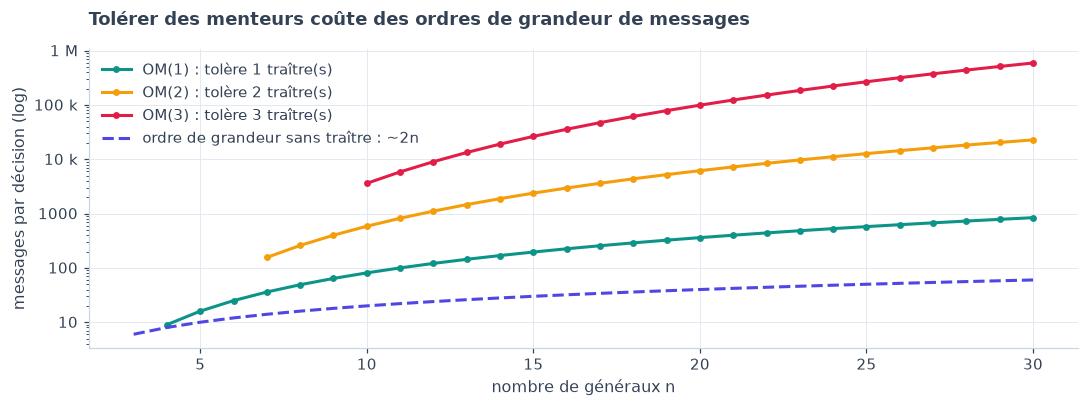

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for m, c in [(1, TEAL), (2, AMBER), (3, ROSE)]:
    ns = np.arange(3 * m + 1, 31)
    msgs = [sum(prod(n - i for i in range(1, k + 1)) for k in range(1, m + 2)) for n in ns]
    ax.semilogy(ns, msgs, "o-", ms=3.5, color=c, label=f"OM({m}) : tolère {m} traître(s)")
ax.semilogy(np.arange(3, 31), 2 * np.arange(3, 31), "--", color=INDIGO, label="ordre de grandeur sans traître : ~2n")
plain_log_axis(ax, "y")
ax.set_xlabel("nombre de généraux n"); ax.set_ylabel("messages par décision (log)")
ax.set_title("Tolérer des menteurs coûte des ordres de grandeur de messages")
ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Une faute byzantine est un nœud qui ment. Atteindre un accord malgré $f$
> menteurs exige plus de $3f$ nœuds (contre $2f+1$ pour des pannes franches) et beaucoup
> plus de messages.

## 2. Quand faut-il tolérer les fautes byzantines ? (section *Uses of Byzantine fault tolerance*)

Un système **tolérant aux fautes byzantines** continue de fonctionner correctement même si
certains nœuds n'obéissent pas au protocole ou si des attaquants interfèrent avec le
réseau. C'est nécessaire dans quelques contextes :

- **aérospatial** : un rayonnement peut corrompre la mémoire ou un registre et faire
  répondre un calculateur de façon arbitraire ; une défaillance coûterait des vies, donc
  les commandes de vol doivent tolérer ces fautes ;
- systèmes à **plusieurs parties qui se méfient** les unes des autres : les mécanismes de
  consensus des cryptomonnaies comme Bitcoin et des chaînes de blocs permettent à des
  parties sans confiance mutuelle de s'accorder sur une transaction sans autorité centrale.

Dans les systèmes du livre, on peut généralement **supposer qu'il n'y en a pas** : dans
un centre de données, tous les nœuds appartiennent à la même organisation et le
rayonnement est assez faible. Les clients d'un système multi-locataire se méfient les uns
des autres, mais on les isole par pare-feu, virtualisation et contrôle d'accès, pas par
des protocoles byzantins, trop coûteux (section 1). Une application web doit s'attendre à
des comportements arbitraires et malveillants des **clients** (navigateurs) : c'est le
rôle de la validation des entrées, de l'échappement (injection SQL, script intersite),
mais le serveur reste l'**autorité** ; dans un réseau pair-à-pair sans autorité centrale,
la tolérance byzantine redevient pertinente.

**Contre les bogues et les attaques, elle n'aide pas.** Un bogue logiciel est une faute
byzantine, mais si tous les nœuds exécutent le même logiciel, tous l'ont : un algorithme
byzantin ne sauve rien. Il faudrait (avec $n = 4$ pour $f = 1$) **quatre implémentations
indépendantes** et espérer qu'un bogue donné n'en touche qu'une. De même, un attaquant
qui compromet un nœud peut probablement compromettre tous les autres, qui font tourner le
même logiciel : authentification, contrôle d'accès, chiffrement et pare-feu restent les
protections principales.

Le livre note que des centres de données en orbite sont à l'étude (où le rayonnement
redeviendrait un problème) et renvoie aux travaux sur la cohérence à terme byzantine et
les CRDT tolérants aux fautes byzantines pour les systèmes pair-à-pair.

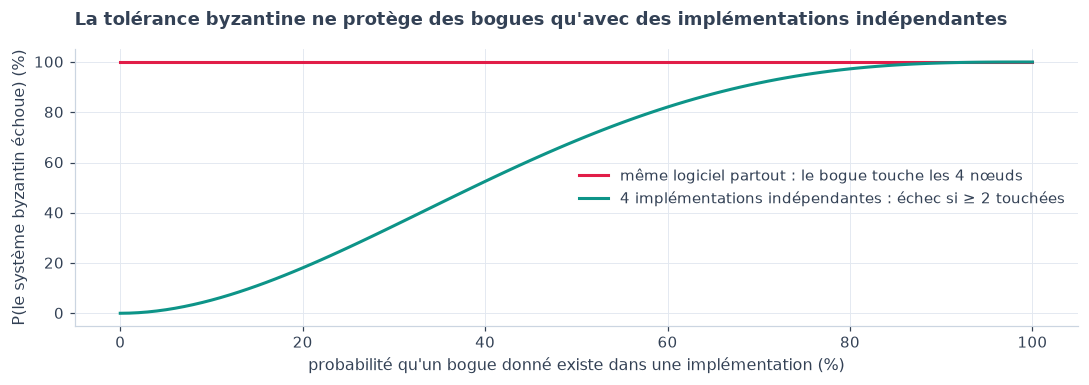

In [5]:
q_bug = np.linspace(0, 1, 101)       # probabilité qu'un bogue donné touche une implémentation
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(q_bug * 100, 100 * np.ones_like(q_bug), color=ROSE, label="même logiciel partout : le bogue touche les 4 nœuds")
p_fail = 1 - ((1 - q_bug) ** 4 + 4 * q_bug * (1 - q_bug) ** 3)          # au moins 2 sur 4 touchées
ax.plot(q_bug * 100, p_fail * 100, color=TEAL, label="4 implémentations indépendantes : échec si ≥ 2 touchées")
ax.set_xlabel("probabilité qu'un bogue donné existe dans une implémentation (%)")
ax.set_ylabel("P(le système byzantin échoue) (%)")
ax.set_title("La tolérance byzantine ne protège des bogues qu'avec des implémentations indépendantes")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

> **À retenir.** La tolérance byzantine sert quand des parties se méfient les unes des
> autres ou quand le matériel peut corrompre les calculs (aérospatial, chaînes de blocs).
> Dans un centre de données, on suppose les nœuds honnêtes : elle coûte trop cher et ne
> protège ni des bogues communs ni des attaquants.

## 3. Les formes faibles de mensonge (section *Weak forms of lying*)

Sans aller jusqu'à la tolérance byzantine complète, il est utile de se prémunir contre des
formes **faibles** de mensonge : messages invalides dus au matériel, aux bogues ou aux
erreurs de configuration. Trois exemples du livre :

- des paquets sont parfois **corrompus** (matériel, pilotes, routeurs) ; les sommes de
  contrôle de TCP et UDP les attrapent généralement, mais pas toujours ; une somme de
  contrôle au niveau de l'application, ou TLS, suffit en général ;
- une application publique doit **valider** ses entrées (échapper les caractères
  dangereux, vérifier qu'une valeur est dans un intervalle raisonnable, limiter la taille
  des chaînes contre le déni de service) ; même un service interne gagne à faire des
  vérifications de base dans ses analyseurs de protocole ;
- un client **NTP** configuré avec plusieurs serveurs écarte celui qui donne une heure
  aberrante, tant que la majorité est correcte (algorithme de Marzullo, cours 3).

**Pourquoi la somme de contrôle de TCP laisse passer des erreurs.** La somme d'Internet
(RFC 1071, utilisée par IP, TCP et UDP) est le complément à un de la **somme** des mots de
16 bits. Une somme ne dépend pas de l'ordre des termes : **échanger deux mots** ne la
change pas. Et en complément à un, 0x0000 et 0xFFFF représentent tous deux zéro.
Comparons-la à un CRC-32 sur des paquets de 512 octets altérés de quatre façons.

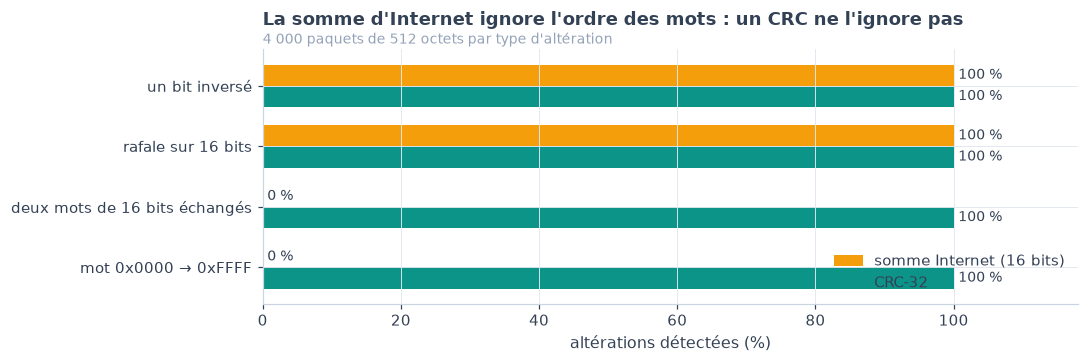

,somme Internet (16 bits),CRC-32
un bit inversé,100.0,100.0
rafale sur 16 bits,100.0,100.0
deux mots de 16 bits échangés,0.0,100.0
mot 0x0000 → 0xFFFF,0.0,100.0


In [6]:
D = pd.DataFrame(ds.detection_rates(n_trials=4000, size=512, seed=3)).T * 100
D.index = ["un bit inversé", "rafale sur 16 bits", "deux mots de 16 bits échangés", "mot 0x0000 → 0xFFFF"]
ax = D.plot.barh(color=[AMBER, TEAL], figsize=(10, 3.4), width=0.7)
annotate_bars(ax, "{:.0f} %", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 118)
ax.set_xlabel("altérations détectées (%)")
ax.set_title("La somme d'Internet ignore l'ordre des mots : un CRC ne l'ignore pas")
subtitle(ax, "4 000 paquets de 512 octets par type d'altération")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
D.round(1)

Les deux codes attrapent toutes les inversions de bit et les rafales courtes, mais la
somme d'Internet ne voit **aucun** échange de mots ni aucune substitution 0x0000/0xFFFF :
précisément le genre d'erreurs que produit un tampon mal recopié par un pilote ou un
routeur bogué. D'où l'intérêt d'une somme de contrôle de bout en bout plus forte dans
l'application (CRC, hachage) ou de TLS, qui authentifie chaque enregistrement.

> **À retenir.** Sans viser la tolérance byzantine, de simples défenses contre les
> mensonges involontaires (sommes de contrôle applicatives, validation des entrées,
> plusieurs serveurs de temps) améliorent nettement la fiabilité.

## 4. Modèles de système (section *System Model and Reality*)

Pour être utile, un algorithme distribué doit tolérer les fautes de ce chapitre sans
dépendre des détails du matériel. On formalise donc ce qui peut arriver dans un **modèle
de système** : une abstraction qui énonce les hypothèses de l'algorithme. Pour le
**temps**, trois modèles :

- **synchrone** : délais réseau, pauses et erreurs d'horloge **bornés** (pas nuls, mais
  jamais au-delà d'une borne connue) ; irréaliste pour la plupart des systèmes ;
- **partiellement synchrone** : le système se comporte comme un système synchrone **la
  plupart du temps**, mais dépasse parfois les bornes, arbitrairement ; c'est le modèle
  réaliste de beaucoup de systèmes ;
- **asynchrone** : aucune hypothèse de temps, pas même d'horloge (donc pas de délai
  d'expiration) ; très restrictif.

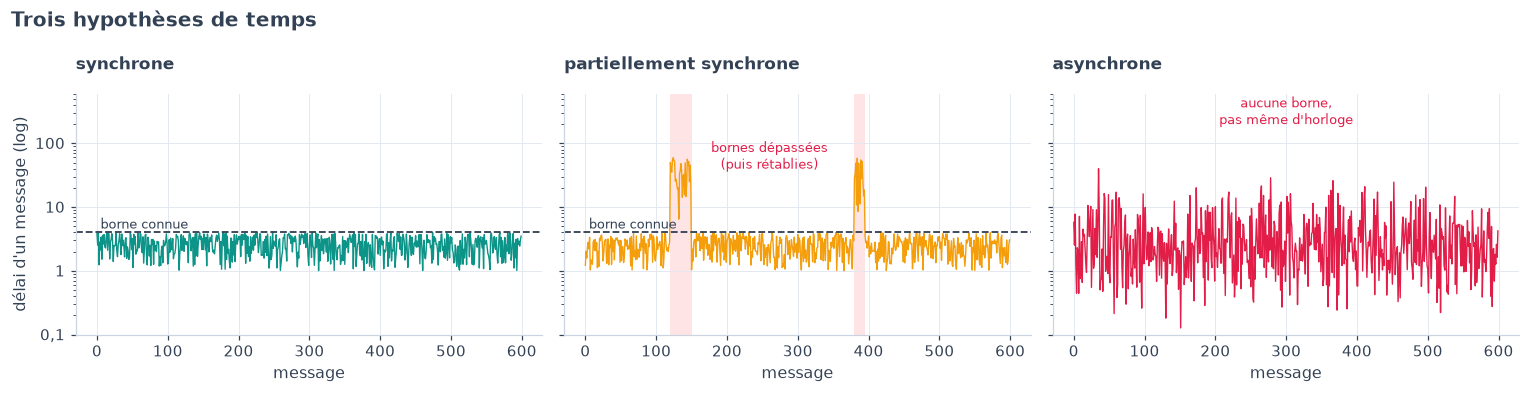

In [7]:
t = np.arange(600)
r = np.random.default_rng(4)
sync = r.uniform(1, 4, t.size)
part = r.uniform(1, 4, t.size)
for a, b in [(120, 150), (380, 395)]:
    part[a:b] = r.uniform(4, 60, b - a)
asyn = np.exp(r.normal(0.8, 1.1, t.size))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, y, titre, c in zip(axes, [sync, part, asyn], ["synchrone", "partiellement synchrone", "asynchrone"], [TEAL, AMBER, ROSE]):
    ax.plot(t, y, color=c, lw=0.9)
    ax.set_yscale("log"); plain_log_axis(ax, "y")
    ax.set_title(titre, fontsize=11); ax.set_xlabel("message")
    if titre != "asynchrone":
        ax.axhline(4, color=SLATE, ls="--", lw=1.2)
        ax.text(5, 4.6, "borne connue", fontsize=8.5, color=SLATE)
axes[1].axvspan(120, 150, color=LIGHT[ROSE], lw=0); axes[1].axvspan(380, 395, color=LIGHT[ROSE], lw=0)
axes[1].text(260, 40, "bornes dépassées\n(puis rétablies)", ha="center", fontsize=8.5, color=ROSE)
axes[2].text(300, 200, "aucune borne,\npas même d'horloge", ha="center", fontsize=8.5, color=ROSE)
axes[0].set_ylim(0.1, 600)
axes[0].set_ylabel("délai d'un message (log)")
plt.suptitle("Trois hypothèses de temps", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

Pour les **pannes de nœuds**, les modèles courants sont :

| modèle | ce qu'un nœud peut faire | ce qui survit |
|---|---|---|
| **panne franche** (crash-stop, fail-stop) | s'arrêter à tout instant, définitivement | rien : le nœud ne revient jamais |
| **panne avec reprise** (crash-recovery) | s'arrêter à tout instant, revenir après un temps inconnu | le stockage stable (disque) ; la mémoire est perdue |
| **byzantine** (arbitraire) | absolument tout, y compris tromper les autres | rien n'est garanti |

Pour modéliser des systèmes réels, le livre recommande le modèle **partiellement
synchrone avec pannes et reprises** : il autorise délais réseau et pauses non bornés et
nœuds qui redémarrent, mais suppose qu'après une interruption, le système finit par
redevenir synchrone.

### Performances dégradées et fonctionnement partiel

La 2e édition ajoute un modèle de faute plus insidieux que la panne : le nœud **ralentit**.
Il répond encore aux contrôles de santé mais est trop lent pour faire du travail utile :
une carte Gigabit qui tombe à 1 kbit/s à cause d'un bogue de pilote, un processus sous
pression mémoire qui passe son temps à collecter, un SSD usé aux performances erratiques,
du matériel perturbé par la chaleur, des vibrations ou un micrologiciel bogué. On parle de
nœud **boiteux** (limping), de **panne grise** (gray failure) ou de **fail-slow** ; c'est
souvent plus difficile à gérer qu'une panne franche. Variante : un processus cesse de
faire **une partie** de son travail (un fil d'arrière-plan planté ou bloqué) tandis que le
reste continue. Simulons un parc de 10 nœuds dont l'un devient 40 fois plus lent à
mi-parcours (`ds.limping_node_sim`), avec un répartiteur qui se fie au contrôle de santé
(« répond-il ? ») ou qui éjecte les nœuds dont la latence médiane observée dépasse cinq
fois celle du parc.

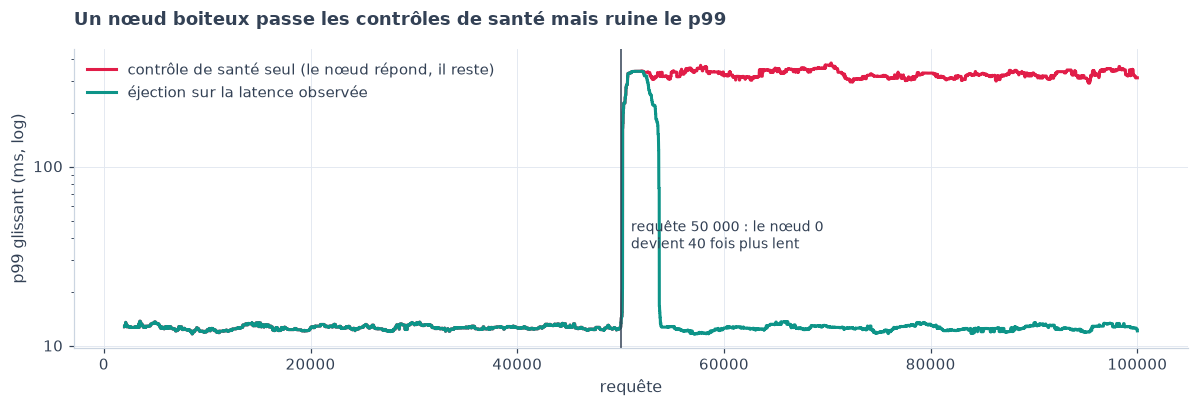

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for pol, c, nom in [("tourniquet", ROSE, "contrôle de santé seul (le nœud répond, il reste)"),
                    ("ejection", TEAL, "éjection sur la latence observée")]:
    res = ds.limping_node_sim(policy=pol, seed=1)
    lat = pd.Series(res["latences"] * 1e3)
    ax.plot(lat.rolling(2000).quantile(0.99).values, color=c, label=nom)
ax.axvline(50_000, color=SLATE, lw=1)
ax.text(51_000, 35, "requête 50 000 : le nœud 0\ndevient 40 fois plus lent", fontsize=9, color=SLATE)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("requête"); ax.set_ylabel("p99 glissant (ms, log)")
ax.set_title("Un nœud boiteux passe les contrôles de santé mais ruine le p99")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Une requête sur dix part vers le nœud boiteux : le p99 grimpe de 10 ms à plus de 300 ms,
et le contrôle de santé, qui ne vérifie que la **présence**, ne voit rien. Il faut juger
un nœud sur ce qu'il **fait** (latences, débit observés par ses pairs), pas seulement sur
le fait qu'il répond.

> **À retenir.** Un modèle de système rend explicites les hypothèses d'un algorithme :
> modèle de temps (synchrone, partiellement synchrone, asynchrone) et modèle de pannes
> (franches, avec reprise, byzantines, dégradées). Le plus réaliste est le modèle
> partiellement synchrone avec pannes et reprises.

## 5. Correction d'un algorithme : sûreté et vivacité (sections *Defining the correctness of an algorithm*, *Distinguishing between safety and liveness*)

Pour dire qu'un algorithme est correct, on énonce ses **propriétés**, comme on dirait
qu'une liste triée est telle que tout élément est plus petit que ceux à sa droite (un
invariant). Pour un générateur de jetons de clôture, le livre propose :

- **unicité** : deux requêtes n'obtiennent jamais le même jeton ;
- **séquence monotone** : si la requête $x$ a obtenu $t_x$, la requête $y$ a obtenu $t_y$,
  et $x$ s'est terminée avant que $y$ commence, alors $t_x < t_y$ ;
- **disponibilité** : un nœud qui demande un jeton et ne tombe pas en panne finit par en
  recevoir un.

Un algorithme est correct **dans un modèle de système** s'il satisfait ses propriétés dans
toutes les situations que ce modèle autorise. Mais si tous les nœuds tombent, aucun
algorithme ne peut rien faire. D'où la distinction :

- une propriété de **sûreté** (safety) : « rien de mal n'arrive » ; unicité et monotonie
  en sont ;
- une propriété de **vivacité** (liveness) : « quelque chose de bien finit par arriver » ;
  la disponibilité en est une (indice : le mot « finit par », eventually ; la cohérence à
  terme, eventual consistency, est une propriété de vivacité).

Les définitions précises sont plus nettes que ces slogans. Une violation de sûreté a une
**date** : on peut montrer l'opération fautive, et le mal est fait, irréversiblement. Une
propriété de vivacité peut ne pas être satisfaite **à un instant donné** (une requête
sans réponse), mais il reste toujours l'espoir qu'elle le soit plus tard. Vérifions cela
sur un générateur de jetons qui tombe en panne à $t = 30$ et redémarre 3 unités plus tard,
selon le modèle **avec reprise** : son compteur est soit sur disque, soit en mémoire
seulement (`ds.token_generator_history`, `ds.check_token_history`).

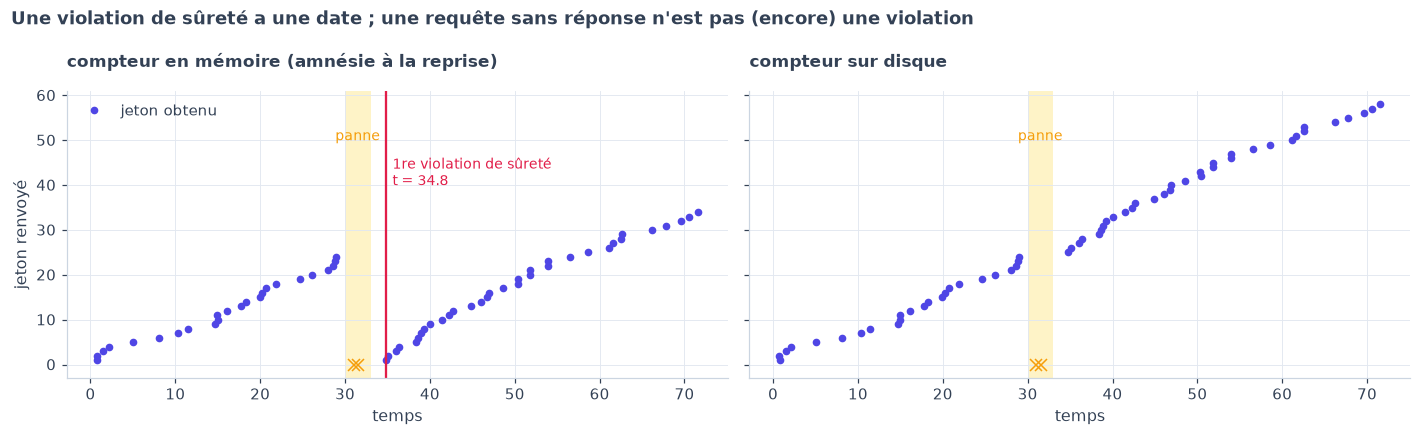

,compteur,violations,types,sans_réponse
0,compteur en mémoire (amnésie à la reprise),324,"[monotonie, unicité]",2
1,compteur sur disque,0,[],2


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
bilan = []
for ax, persist, titre in zip(axes, [False, True], ["compteur en mémoire (amnésie à la reprise)", "compteur sur disque"]):
    h = ds.token_generator_history(persist=persist, seed=0)
    chk = ds.check_token_history(h)
    ok = [x for x in h if x.end is not None]
    ax.plot([x.end for x in ok], [x.token for x in ok], "o", ms=4, color=INDIGO, label="jeton obtenu")
    ax.axvspan(30, 33, color=LIGHT[AMBER], lw=0)
    ax.text(31.5, 50, "panne", ha="center", color=AMBER, fontsize=9)
    for x in h:
        if x.end is None:
            ax.plot(x.start, 0, "x", color=AMBER, ms=8)
    if chk["premiere"] is not None:
        ax.axvline(chk["premiere"], color=ROSE, lw=1.5)
        ax.text(chk["premiere"] + 0.8, 40, f"1re violation de sûreté\nt = {chk['premiere']:.1f}", color=ROSE, fontsize=9)
    ax.set_title(titre, fontsize=11); ax.set_xlabel("temps")
    bilan.append(dict(compteur=titre, violations=len(chk["violations"]),
                      types=sorted({v[0] for v in chk["violations"]}), sans_réponse=chk["sans_reponse"]))
axes[0].set_ylabel("jeton renvoyé"); axes[0].legend(loc="upper left")
plt.suptitle("Une violation de sûreté a une date ; une requête sans réponse n'est pas (encore) une violation",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
pd.DataFrame(bilan)

Avec un compteur en mémoire, le générateur redémarre à 1 et renvoie des jetons déjà
distribués : unicité et monotonie sont violées, et le vérificateur désigne **l'instant
exact** de la première violation. Rien ne pourra la réparer : si deux clients ont reçu le
même jeton, la clôture du cours 4 ne protège plus rien. Avec le compteur sur disque, aucune
violation. Dans les deux cas, les requêtes arrivées pendant la panne (croix) sont restées
sans réponse : ce n'est **pas** une violation de vivacité, car rien n'interdit qu'elles
soient servies plus tard ; sur un historique fini, on ne peut jamais prouver qu'une
propriété de vivacité est violée.

Cette distinction aide à raisonner dans des modèles difficiles : on exige généralement
que la **sûreté tienne toujours**, même si tous les nœuds tombent ou si tout le réseau
défaille (l'algorithme ne doit jamais renvoyer un résultat faux), et l'on autorise des
**réserves** pour la vivacité (une réponse n'est due que si une majorité de nœuds est en
vie et si le réseau finit par se rétablir, ce que garantit justement le modèle
partiellement synchrone).

> **À retenir.** On définit la correction par des propriétés. Une violation de sûreté a
> une date et est irréversible : la sûreté doit tenir dans tous les cas. La vivacité
> (« finit par ») peut être conditionnée au retour d'une majorité et du réseau.

## 6. Des modèles au monde réel (section *Mapping system models to the real world*)

Les modèles sont des simplifications, et la réalité revient mordre au moment de
l'implémentation. Les algorithmes avec reprise supposent que le stockage stable survit
aux pannes : et si le disque est corrompu ou effacé par une erreur matérielle ou de
configuration ? Et si un serveur, à cause d'un bogue de micrologiciel, ne reconnaît plus
ses disques au redémarrage ? Les algorithmes à **quorum** supposent qu'un nœud se
souvient de ce qu'il dit avoir stocké ; un nœud **amnésique** casse la condition de
quorum. Prenons 5 répliques, des écritures et des lectures sur des quorums de 3
($w + r > n$, chapitre 6) : une écriture a été acquittée par 3 répliques,
puis $k$ d'entre elles perdent leur disque et reviennent vides. Quelle est la probabilité
qu'une lecture de quorum ne voie plus la valeur ?

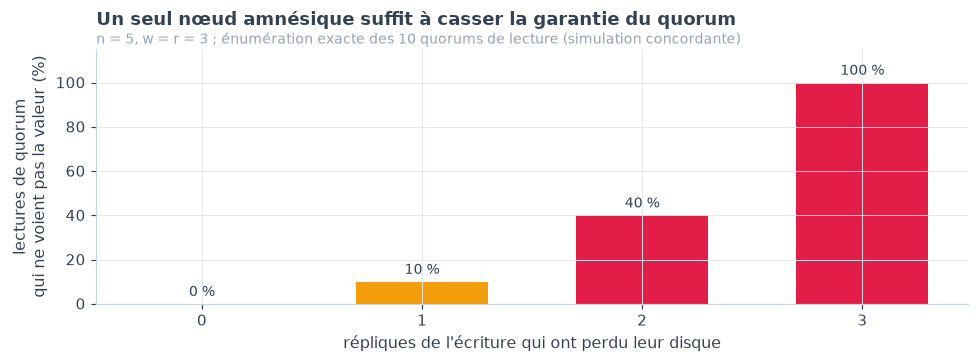

,amnésiques,exact,simulé
0,0,0.0,0.0
1,1,10.0,9.7
2,2,40.0,39.9
3,3,100.0,100.0


In [10]:
n, w, rq_ = 5, 3, 3
noeuds = range(n)
W = set(range(w))                          # répliques qui ont acquitté l'écriture
rows = []
for k in range(0, w + 1):
    survivants = W - set(range(k))         # k répliques amnésiques parmi celles de l'écriture
    quorums = list(itertools.combinations(noeuds, rq_))
    rate = np.mean([not (set(R) & survivants) for R in quorums]) * 100
    sim = np.mean([not (set(rng.choice(n, rq_, replace=False)) & survivants) for _ in range(20_000)]) * 100
    rows.append(dict(amnésiques=k, exact=rate, simulé=sim))
A = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(A.amnésiques, A.exact, color=[TEAL, AMBER, ROSE, ROSE], width=0.6)
annotate_bars(ax, "{:.0f} %")
ax.set_xticks(A.amnésiques); ax.set_xlabel("répliques de l'écriture qui ont perdu leur disque")
ax.set_ylabel("lectures de quorum\nqui ne voient pas la valeur (%)"); ax.set_ylim(0, 115)
ax.set_title("Un seul nœud amnésique suffit à casser la garantie du quorum")
subtitle(ax, "n = 5, w = r = 3 ; énumération exacte des 10 quorums de lecture (simulation concordante)")
plt.tight_layout(); plt.show()
A.round(1)

Sans amnésie, toute lecture de quorum voit la valeur (c'est la garantie $w + r > n$). Avec
**une seule** réplique amnésique, une lecture sur dix la manque, et l'algorithme, prouvé
correct dans son modèle, renvoie une valeur périmée. On pourrait adopter un modèle où le
stockage stable survit **presque** toujours, mais on raisonne alors beaucoup plus
difficilement.

La description théorique peut déclarer impossibles certaines situations, et dans un
système non byzantin il faut bien faire des hypothèses. Une implémentation réelle doit
pourtant souvent traiter le cas « impossible », même si ce n'est que par un
`printf("Sucks to be you")` suivi de `exit(666)`, c'est-à-dire en laissant un humain
réparer (c'est une différence entre informatique théorique et génie logiciel). Les modèles
abstraits n'en sont pas moins précieux : ils ramènent la complexité du réel à un ensemble
de fautes sur lesquelles on peut raisonner systématiquement.

> **À retenir.** Un algorithme n'est correct que dans son modèle ; quand la réalité sort
> du modèle (disque effacé, nœud amnésique), ses garanties tombent. Il faut quand même
> prévoir ces cas, ne serait-ce que pour alerter un humain.

## Synthèse

- Les nœuds sont supposés **honnêtes** ; tolérer des menteurs (fautes byzantines) exige
  $n > 3f$ et beaucoup de messages, utile seulement entre parties qui se méfient ou face à
  un matériel peu fiable.
- De **simples défenses** contre les mensonges involontaires (sommes de contrôle
  applicatives, validation, plusieurs serveurs de temps) suffisent le plus souvent.
- Un **modèle de système** fixe les hypothèses (temps, pannes) ; le plus réaliste est
  partiellement synchrone avec pannes et reprises.
- La correction se définit par des propriétés de **sûreté** (toujours vraies) et de
  **vivacité** (« finit par », sous conditions).
- Les modèles simplifient la réalité : il faut tout de même traiter les cas « impossibles », et vérifier les algorithmes (cours 6).

Liens : quorums au chapitre 6 ; consensus, linéarisabilité et services de
coordination au chapitre 10, où les algorithmes sont conçus pour le modèle
partiellement synchrone avec reprise.